In [3]:
import numpy as np
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline 
import sqlite3

In [135]:
!pip install gdown

In [137]:
import sqlite3
import os

db_path = "zomato_rawdata.sqlite"

if not os.path.exists(db_path):
    import gdown

    url = "https://drive.google.com/uc?id=1pBwO5gWe60l4-IaaZs96G4hwnwaXgr0W"
    gdown.download(url, db_path, quiet=False)

con = sqlite3.connect(db_path)

Downloading...
From (original): https://drive.google.com/uc?id=1pBwO5gWe60l4-IaaZs96G4hwnwaXgr0W
From (redirected): https://drive.google.com/uc?id=1pBwO5gWe60l4-IaaZs96G4hwnwaXgr0W&confirm=t&uuid=8891dd0f-ac8a-4f0b-a6f5-c93e57496b43
To: C:\Users\noela\zomato_rawdata.sqlite
100%|██████████| 603M/603M [14:39<00:00, 686kB/s]  


In [138]:
pd.read_sql_query("SELECT * FROM Users",con).head(2)

,index,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,0,https://www.zomato.com/bangalore/jalsa-banasha...,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.1/5,775,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari
1,1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1/5,787,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari


In [6]:
df=pd.read_sql_query("SELECT * FROM Users",con)

In [7]:
df.columns

Index(['index', 'url', 'address', 'name', 'online_order', 'book_table', 'rate',
       'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='str')

In [8]:
df.shape

(51717, 18)

In [9]:
df.isnull()

,index,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51712,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False
51713,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False
51714,False,False,False,False,False,False,True,False,True,False,False,True,False,False,False,False,False,False
51715,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [10]:
df.isnull().sum()

index                              0
url                                0
address                            0
name                               0
online_order                       0
book_table                         0
rate                            7775
votes                              0
phone                           1208
location                          21
rest_type                        227
dish_liked                     28078
cuisines                          45
approx_cost(for two people)      346
reviews_list                       0
menu_item                          0
listed_in(type)                    0
listed_in(city)                    0
dtype: int64

In [11]:
(df.isnull().sum()/len(df))*100

index                           0.000000
url                             0.000000
address                         0.000000
name                            0.000000
online_order                    0.000000
book_table                      0.000000
rate                           15.033741
votes                           0.000000
phone                           2.335789
location                        0.040606
rest_type                       0.438927
dish_liked                     54.291626
cuisines                        0.087012
approx_cost(for two people)     0.669026
reviews_list                    0.000000
menu_item                       0.000000
listed_in(type)                 0.000000
listed_in(city)                 0.000000
dtype: float64

In [12]:
df['rate'].unique()

<ArrowStringArray>
[ '4.1/5',  '3.8/5',  '3.7/5',  '3.6/5',  '4.6/5',  '4.0/5',  '4.2/5',
  '3.9/5',  '3.1/5',  '3.0/5',  '3.2/5',  '3.3/5',  '2.8/5',  '4.4/5',
  '4.3/5',    'NEW',  '2.9/5',  '3.5/5',      nan,  '2.6/5', '3.8 /5',
  '3.4/5',  '4.5/5',  '2.5/5',  '2.7/5',  '4.7/5',  '2.4/5',  '2.2/5',
  '2.3/5', '3.4 /5',      '-', '3.6 /5',  '4.8/5', '3.9 /5', '4.2 /5',
 '4.0 /5', '4.1 /5', '3.7 /5', '3.1 /5', '2.9 /5', '3.3 /5', '2.8 /5',
 '3.5 /5', '2.7 /5', '2.5 /5', '3.2 /5', '2.6 /5', '4.5 /5', '4.3 /5',
 '4.4 /5',  '4.9/5',  '2.1/5',  '2.0/5',  '1.8/5', '4.6 /5', '4.9 /5',
 '3.0 /5', '4.8 /5', '2.3 /5', '4.7 /5', '2.4 /5', '2.1 /5', '2.2 /5',
 '2.0 /5', '1.8 /5']
Length: 65, dtype: str

In [13]:
df['rate'] = df['rate'].replace(["NEW", "-"], np.nan)

In [14]:
df['rate'].unique()

<ArrowStringArray>
[ '4.1/5',  '3.8/5',  '3.7/5',  '3.6/5',  '4.6/5',  '4.0/5',  '4.2/5',
  '3.9/5',  '3.1/5',  '3.0/5',  '3.2/5',  '3.3/5',  '2.8/5',  '4.4/5',
  '4.3/5',      nan,  '2.9/5',  '3.5/5',  '2.6/5', '3.8 /5',  '3.4/5',
  '4.5/5',  '2.5/5',  '2.7/5',  '4.7/5',  '2.4/5',  '2.2/5',  '2.3/5',
 '3.4 /5', '3.6 /5',  '4.8/5', '3.9 /5', '4.2 /5', '4.0 /5', '4.1 /5',
 '3.7 /5', '3.1 /5', '2.9 /5', '3.3 /5', '2.8 /5', '3.5 /5', '2.7 /5',
 '2.5 /5', '3.2 /5', '2.6 /5', '4.5 /5', '4.3 /5', '4.4 /5',  '4.9/5',
  '2.1/5',  '2.0/5',  '1.8/5', '4.6 /5', '4.9 /5', '3.0 /5', '4.8 /5',
 '2.3 /5', '4.7 /5', '2.4 /5', '2.1 /5', '2.2 /5', '2.0 /5', '1.8 /5']
Length: 63, dtype: str

In [15]:
df['rate']=df['rate'].apply(lambda x: float((x.split("/"))[0]) if type(x)==str else  x )

In [16]:
x=pd.crosstab(df['rate'],df['online_order'])

<Axes: xlabel='rate'>

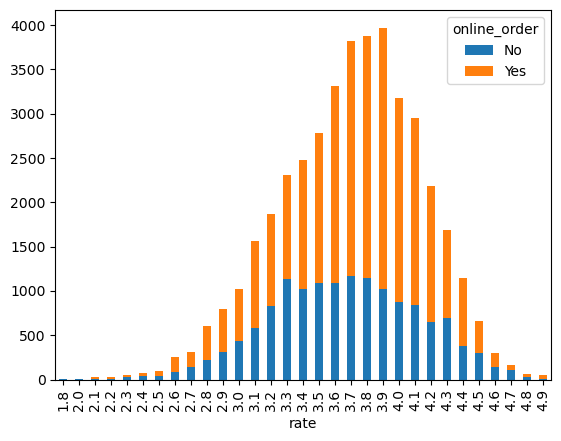

In [17]:
x.plot(kind='bar',stacked=True)

In [18]:
x.sum(axis=1).astype(float)

rate
1.8       5.0
2.0      11.0
2.1      24.0
2.2      26.0
2.3      51.0
2.4      70.0
2.5     101.0
2.6     260.0
2.7     307.0
2.8     600.0
2.9     802.0
3.0    1023.0
3.1    1561.0
3.2    1873.0
3.3    2310.0
3.4    2476.0
3.5    2784.0
3.6    3316.0
3.7    3821.0
3.8    3873.0
3.9    3972.0
4.0    3183.0
4.1    2948.0
4.2    2184.0
4.3    1693.0
4.4    1147.0
4.5     656.0
4.6     300.0
4.7     167.0
4.8      66.0
4.9      55.0
dtype: float64

In [19]:
normalized_x =x.div(x.sum(axis=1).astype(float),axis=0)

<Axes: xlabel='rate'>

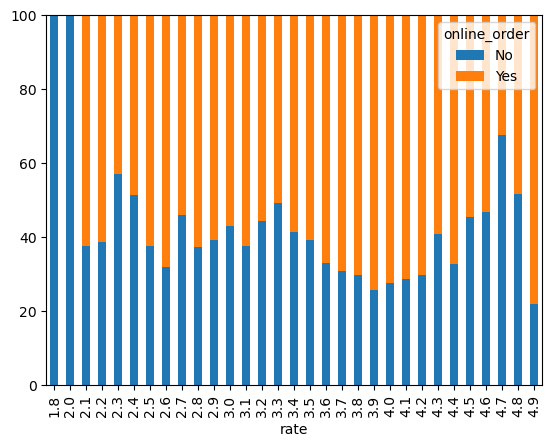

In [20]:
(normalized_x*100).plot(kind='bar',stacked=True)

In [21]:
df['rest_type'].isnull().sum()

227

In [22]:
data = df.dropna(subset=['rest_type'])

In [23]:
data['rest_type'].unique()

<ArrowStringArray>
[                'Casual Dining',           'Cafe, Casual Dining',
                   'Quick Bites',           'Casual Dining, Cafe',
                          'Cafe',             'Quick Bites, Cafe',
             'Cafe, Quick Bites',                      'Delivery',
                          'Mess',                'Dessert Parlor',
        'Bakery, Dessert Parlor',                           'Pub',
                        'Bakery',            'Takeaway, Delivery',
                   'Fine Dining',                 'Beverage Shop',
                    'Sweet Shop',                           'Bar',
    'Beverage Shop, Quick Bites',                 'Confectionery',
    'Quick Bites, Beverage Shop',    'Dessert Parlor, Sweet Shop',
           'Bakery, Quick Bites',       'Sweet Shop, Quick Bites',
                         'Kiosk',                    'Food Truck',
   'Quick Bites, Dessert Parlor', 'Beverage Shop, Dessert Parlor',
                      'Takeaway',          

In [24]:
data['rest_type'].str.contains('Quick Bites')

0        False
1        False
2        False
3         True
4        False
         ...  
51712    False
51713    False
51714    False
51715    False
51716    False
Name: rest_type, Length: 51490, dtype: bool

In [25]:
quick_bites=data[data['rest_type'].str.contains('Quick Bites')]

In [26]:
quick_bites.columns

Index(['index', 'url', 'address', 'name', 'online_order', 'book_table', 'rate',
       'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines',
       'approx_cost(for two people)', 'reviews_list', 'menu_item',
       'listed_in(type)', 'listed_in(city)'],
      dtype='str')

In [27]:
quick_bites['reviews_list']

3        [('Rated 4.0', "RATED\n  Great food and proper...
23       [('Rated 4.0', "RATED\n  So, went here with fr...
26       [('Rated 5.0', 'RATED\n  please provide some e...
31       [('Rated 1.0', "RATED\n  Worst restaurant ever...
34       [('Rated 3.0', 'RATED\n  Not worth for the mon...
                               ...                        
51641    [('Rated 2.0', "RATED\n  Food is not upto the ...
51642                                                   []
51643                                                   []
51644                                                   []
51645    [('Rated 5.0', "RATED\n  I was randomly lookin...
Name: reviews_list, Length: 20639, dtype: str

In [28]:
quick_bites['reviews_list']=quick_bites['reviews_list'].apply(lambda x:x.lower())

In [29]:
from nltk.corpus import RegexpTokenizer,stopwords

In [30]:
tokenizer=RegexpTokenizer("[a-zA-Z]+")

In [31]:
tokenizer

RegexpTokenizer(pattern='[a-zA-Z]+', gaps=False, discard_empty=True, flags=re.UNICODE|re.MULTILINE|re.DOTALL)

In [32]:
reviews_token=quick_bites['reviews_list'].apply(tokenizer.tokenize)

In [33]:
reviews_token

3        [rated, rated, n, great, food, and, proper, ka...
23       [rated, rated, n, so, went, here, with, friend...
26       [rated, rated, n, please, provide, some, extra...
31       [rated, rated, n, worst, restaurant, ever, veg...
34       [rated, rated, n, not, worth, for, the, money,...
                               ...                        
51641    [rated, rated, n, food, is, not, upto, the, ma...
51642                                                   []
51643                                                   []
51644                                                   []
51645    [rated, rated, n, i, was, randomly, looking, o...
Name: reviews_list, Length: 20639, dtype: object

In [34]:
stop=stopwords.words("english")

In [35]:
stop.extend(['rated','n','nan','x','xa','f','c'])

In [36]:
review_cleaned= reviews_token.apply(lambda each_review:[token for token in each_review  if token not in stop])

In [37]:
review_cleaned

3        [great, food, proper, karnataka, style, full, ...
23       [went, friends, tea, ambience, striking, say, ...
26       [please, provide, extra, sambal, quantity, les...
31       [worst, restaurant, ever, veg, manchurian, wor...
34       [worth, money, pay, ambience, good, enough, se...
                               ...                        
51641    [food, upto, mark, nquantity, food, little, nc...
51642                                                   []
51643                                                   []
51644                                                   []
51645    [randomly, looking, zomato, burger, show, rest...
Name: reviews_list, Length: 20639, dtype: object

In [38]:
type (review_cleaned)

pandas.Series

In [39]:
total_reviews_2D=list(review_cleaned)

In [40]:
total_review_1D=[]
for review in total_reviews_2D:
    for word in review:
        total_review_1D.append(word)
        
        
    

In [41]:
from nltk import FreqDist

In [42]:
fd=FreqDist()

In [43]:
for word in total_review_1D:
    fd[word]=fd[word]+1

In [44]:
fd.most_common(20)

[('food', 170672),
 ('good', 169085),
 ('place', 142338),
 ('chicken', 76826),
 ('taste', 70602),
 ('ordered', 55485),
 ('try', 43663),
 ('one', 43359),
 ('also', 42296),
 ('like', 41979),
 ('service', 39651),
 ('time', 38409),
 ('order', 37012),
 ('really', 36239),
 ('biryani', 35488),
 ('best', 33589),
 ('restaurant', 32669),
 ('great', 32601),
 ('quality', 30940),
 ('nice', 30744)]

<Axes: xlabel='Samples', ylabel='Counts'>

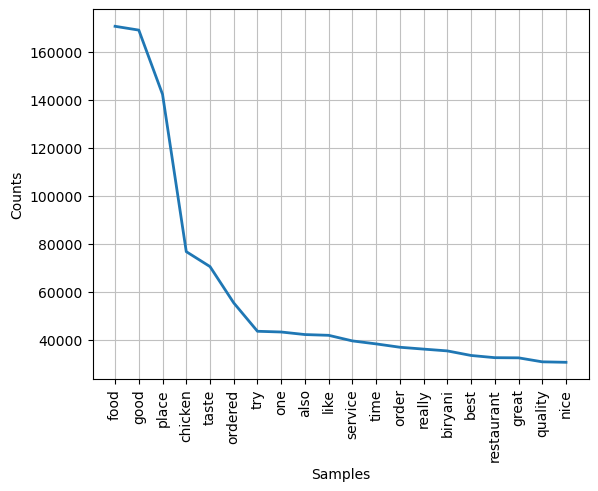

In [45]:
fd.plot(20)

In [46]:
from nltk import FreqDist,bigrams,trigrams

In [47]:
bi_grams= bigrams(total_review_1D)

In [48]:
bi_grams

<generator object bigrams at 0x000002116439EF80>

In [49]:
fd_bigrams=FreqDist()
for bigram in bi_grams:
    fd_bigrams[bigram]=fd_bigrams[bigram]+1
     

In [50]:
fd_bigrams.most_common(20)

[(('must', 'try'), 13250),
 (('good', 'food'), 11534),
 (('food', 'good'), 11139),
 (('really', 'good'), 9919),
 (('north', 'indian'), 9059),
 (('pocket', 'friendly'), 8170),
 (('taste', 'good'), 8122),
 (('good', 'place'), 8059),
 (('value', 'money'), 7139),
 (('south', 'indian'), 7032),
 (('good', 'taste'), 6593),
 (('visit', 'place'), 6296),
 (('also', 'good'), 6170),
 (('one', 'best'), 6116),
 (('fried', 'rice'), 5960),
 (('quality', 'food'), 5822),
 (('chicken', 'biryani'), 5536),
 (('non', 'veg'), 5296),
 (('ordered', 'chicken'), 5256),
 (('indian', 'food'), 4992)]

<Axes: xlabel='Samples', ylabel='Counts'>

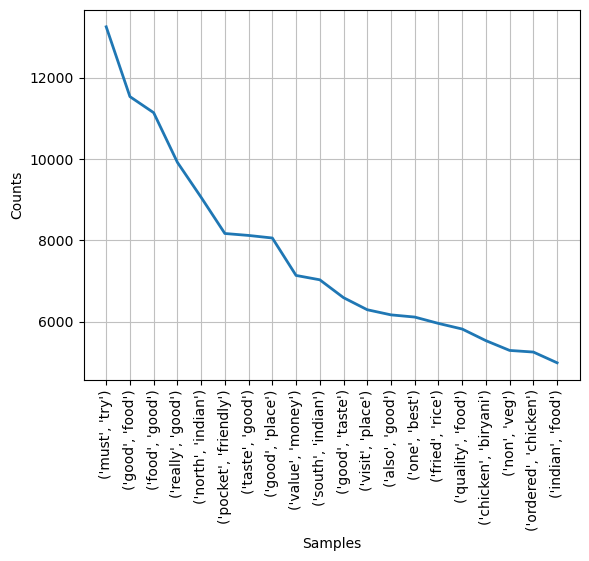

In [51]:
fd_bigrams.plot(20)

In [52]:
fd_bigrams.most_common(100)

[(('must', 'try'), 13250),
 (('good', 'food'), 11534),
 (('food', 'good'), 11139),
 (('really', 'good'), 9919),
 (('north', 'indian'), 9059),
 (('pocket', 'friendly'), 8170),
 (('taste', 'good'), 8122),
 (('good', 'place'), 8059),
 (('value', 'money'), 7139),
 (('south', 'indian'), 7032),
 (('good', 'taste'), 6593),
 (('visit', 'place'), 6296),
 (('also', 'good'), 6170),
 (('one', 'best'), 6116),
 (('fried', 'rice'), 5960),
 (('quality', 'food'), 5822),
 (('chicken', 'biryani'), 5536),
 (('non', 'veg'), 5296),
 (('ordered', 'chicken'), 5256),
 (('indian', 'food'), 4992),
 (('masala', 'dosa'), 4828),
 (('good', 'good'), 4758),
 (('home', 'delivery'), 4721),
 (('food', 'quality'), 4407),
 (('small', 'place'), 4375),
 (('must', 'visit'), 4347),
 (('nice', 'place'), 4287),
 (('tasty', 'food'), 4057),
 (('best', 'place'), 3910),
 (('great', 'place'), 3708),
 (('good', 'service'), 3665),
 (('first', 'time'), 3558),
 (('take', 'away'), 3530),
 (('good', 'quality'), 3381),
 (('place', 'good'),

In [53]:
tri_grams= trigrams(total_review_1D)

In [54]:
tri_grams

<generator object trigrams at 0x00000211643D73E0>

In [55]:
fd_trigrams=FreqDist()
for trigram in tri_grams:
    fd_trigrams[trigram]=fd_trigrams[trigram]+1
     

In [56]:
fd_trigrams.most_common(30)

[(('north', 'indian', 'food'), 3079),
 (('paneer', 'butter', 'masala'), 1638),
 (('must', 'visit', 'place'), 1594),
 (('south', 'indian', 'food'), 1486),
 (('good', 'food', 'good'), 1367),
 (('ordered', 'chicken', 'biryani'), 1275),
 (('pocket', 'friendly', 'place'), 1059),
 (('chicken', 'fried', 'rice'), 1050),
 (('food', 'really', 'good'), 1021),
 (('veg', 'non', 'veg'), 1013),
 (('worst', 'food', 'ever'), 939),
 (('like', 'home', 'made'), 897),
 (('must', 'try', 'place'), 896),
 (('good', 'taste', 'good'), 827),
 (('good', 'value', 'money'), 825),
 (('south', 'indian', 'breakfast'), 816),
 (('home', 'made', 'food'), 787),
 (('food', 'reasonable', 'price'), 746),
 (('good', 'quality', 'food'), 732),
 (('ghar', 'ka', 'khana'), 693),
 (('keep', 'good', 'work'), 692),
 (('taste', 'really', 'good'), 686),
 (('home', 'cooked', 'food'), 653),
 (('quality', 'food', 'good'), 649),
 (('food', 'quality', 'good'), 629),
 (('food', 'taste', 'good'), 626),
 (('worth', 'every', 'penny'), 613),
 ((

<Axes: xlabel='Samples', ylabel='Counts'>

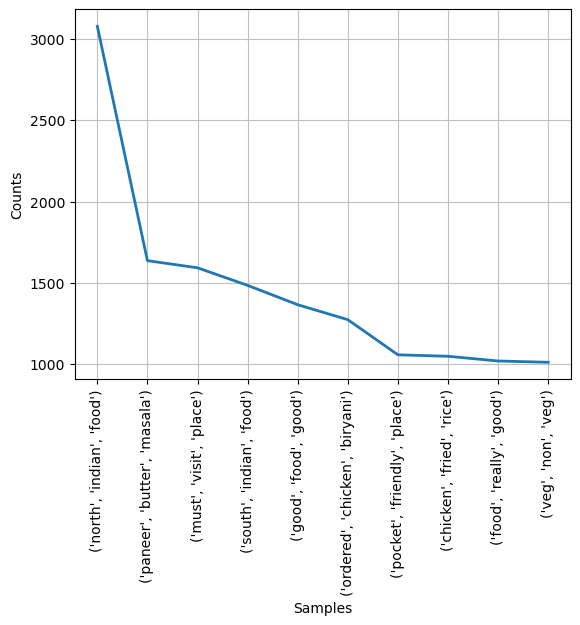

In [57]:
fd_trigrams.plot(10)

In [58]:
!pip install geocoder
!pip install geopy

In [59]:
len(df['location'].unique())

94

In [60]:
df['location'] = df['location'] + " , Bangalore  , Karnataka , India "

In [61]:
df['location']

0           Banashankari , Bangalore  , Karnataka , India 
1           Banashankari , Bangalore  , Karnataka , India 
2           Banashankari , Bangalore  , Karnataka , India 
3           Banashankari , Bangalore  , Karnataka , India 
4           Basavanagudi , Bangalore  , Karnataka , India 
                               ...                        
51712         Whitefield , Bangalore  , Karnataka , India 
51713         Whitefield , Bangalore  , Karnataka , India 
51714         Whitefield , Bangalore  , Karnataka , India 
51715    ITPL Main Road, Whitefield , Bangalore  , Karn...
51716    ITPL Main Road, Whitefield , Bangalore  , Karn...
Name: location, Length: 51717, dtype: str

In [62]:
df['location'].unique()

<ArrowStringArray>
[                 'Banashankari , Bangalore  , Karnataka , India ',
                  'Basavanagudi , Bangalore  , Karnataka , India ',
                   'Mysore Road , Bangalore  , Karnataka , India ',
                     'Jayanagar , Bangalore  , Karnataka , India ',
            'Kumaraswamy Layout , Bangalore  , Karnataka , India ',
          'Rajarajeshwari Nagar , Bangalore  , Karnataka , India ',
                   'Vijay Nagar , Bangalore  , Karnataka , India ',
                   'Uttarahalli , Bangalore  , Karnataka , India ',
                      'JP Nagar , Bangalore  , Karnataka , India ',
               'South Bangalore , Bangalore  , Karnataka , India ',
                   'City Market , Bangalore  , Karnataka , India ',
                    'Nagarbhavi , Bangalore  , Karnataka , India ',
             'Bannerghatta Road , Bangalore  , Karnataka , India ',
                           'BTM , Bangalore  , Karnataka , India ',
               'Kanakapura Ro

In [63]:
df_copy = df.copy()

In [64]:
df_copy['location'].isnull().sum()

21

In [65]:
df_copy = df_copy.dropna(subset=['location'])

In [66]:
df_copy['location'].isnull().sum()

0

In [67]:
locations = pd.DataFrame(df_copy['location'].unique())

In [68]:
locations.columns = ['name']

In [69]:
from geopy.geocoders import Photon

geolocator = Photon(user_agent="noel_zomato_project_8472", timeout=10)

In [70]:
import time

lat=[]
lon=[]

for location in locations['name']:
    location = geolocator.geocode(location + ", Bangalore, India")
    if location is None:
        lat.append(np.nan)
        lon.append(np.nan)
    else:
        lat.append(location.latitude)
        lon.append(location.longitude)
    time.sleep(1)

In [76]:
locations['latitude'] = lat
locations['longitude'] = lon

In [77]:
locations

,name,latitude,longitude
0,"Banashankari , Bangalore , Karnataka , India",12.939333,77.553982
1,"Basavanagudi , Bangalore , Karnataka , India",12.941726,77.575502
2,"Mysore Road , Bangalore , Karnataka , India",12.973009,77.580471
3,"Jayanagar , Bangalore , Karnataka , India",12.941849,77.586898
4,"Kumaraswamy Layout , Bangalore , Karnataka , ...",12.906768,77.559502
...,...,...,...
88,"West Bangalore , Bangalore , Karnataka , India",12.943934,77.509184
89,"Magadi Road , Bangalore , Karnataka , India",12.975653,77.555355
90,"Yelahanka , Bangalore , Karnataka , India",13.197605,77.707486
91,"Sahakara Nagar , Bangalore , Karnataka , India",13.062147,77.580061


In [78]:
locations.isnull().sum()

name         0
latitude     0
longitude    0
dtype: int64

In [74]:
locations.isnull().sum()

name    0
dtype: int64

In [83]:
df['cuisines'].isnull().sum()

45

In [84]:
df=df.dropna(subset=['cuisines'])

In [87]:
north_india=df[df['cuisines'].str.contains(' North Indian')]

In [88]:
north_india.shape

(8786, 18)

In [89]:
north_india.head(2)

,index,url,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city)
1,1,https://www.zomato.com/bangalore/spice-elephan...,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.1,787,080 41714161,"Banashankari , Bangalore , Karnataka , India",Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari
3,3,https://www.zomato.com/bangalore/addhuri-udupi...,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.7,88,+91 9620009302,"Banashankari , Bangalore , Karnataka , India",Quick Bites,Masala Dosa,"South Indian, North Indian",300,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari


In [90]:
north_india['location']

1           Banashankari , Bangalore  , Karnataka , India 
3           Banashankari , Bangalore  , Karnataka , India 
20          Banashankari , Bangalore  , Karnataka , India 
53             Jayanagar , Bangalore  , Karnataka , India 
55          Banashankari , Bangalore  , Karnataka , India 
                               ...                        
51700         Whitefield , Bangalore  , Karnataka , India 
51701         Whitefield , Bangalore  , Karnataka , India 
51708         Whitefield , Bangalore  , Karnataka , India 
51711         Whitefield , Bangalore  , Karnataka , India 
51716    ITPL Main Road, Whitefield , Bangalore  , Karn...
Name: location, Length: 8786, dtype: str

In [92]:
north_india['location'].value_counts()

location
BTM , Bangalore  , Karnataka , India                       951
HSR , Bangalore  , Karnataka , India                       477
JP Nagar , Bangalore  , Karnataka , India                  446
Koramangala 5th Block , Bangalore  , Karnataka , India     432
Whitefield , Bangalore  , Karnataka , India                382
                                                          ... 
North Bangalore , Bangalore  , Karnataka , India             3
Old Madras Road , Bangalore  , Karnataka , India             2
Central Bangalore , Bangalore  , Karnataka , India           2
Hebbal , Bangalore  , Karnataka , India                      2
West Bangalore , Bangalore  , Karnataka , India              1
Name: count, Length: 88, dtype: int64

In [101]:
north_india_rest_count = (
    north_india['location']
    .value_counts()
    .reset_index()
    .rename(columns={"location": "name", "count": "count"})
)

In [98]:
north_india_rest_count

,Name,count
0,"BTM , Bangalore , Karnataka , India",951
1,"HSR , Bangalore , Karnataka , India",477
2,"JP Nagar , Bangalore , Karnataka , India",446
3,"Koramangala 5th Block , Bangalore , Karnataka...",432
4,"Whitefield , Bangalore , Karnataka , India",382
...,...,...
83,"North Bangalore , Bangalore , Karnataka , India",3
84,"Old Madras Road , Bangalore , Karnataka , India",2
85,"Central Bangalore , Bangalore , Karnataka , I...",2
86,"Hebbal , Bangalore , Karnataka , India",2


In [103]:
north_india_rest_count.merge(locations, on='name')

,name,count,latitude,longitude
0,"BTM , Bangalore , Karnataka , India",951,12.916961,77.608947
1,"HSR , Bangalore , Karnataka , India",477,12.912200,77.648903
2,"JP Nagar , Bangalore , Karnataka , India",446,12.913118,77.589687
3,"Koramangala 5th Block , Bangalore , Karnataka...",432,12.934843,77.618977
4,"Whitefield , Bangalore , Karnataka , India",382,12.992763,77.702766
...,...,...,...,...
83,"North Bangalore , Bangalore , Karnataka , India",3,12.976794,77.590082
84,"Old Madras Road , Bangalore , Karnataka , India",2,12.985913,77.644907
85,"Central Bangalore , Bangalore , Karnataka , I...",2,12.880209,77.665844
86,"Hebbal , Bangalore , Karnataka , India",2,13.040041,77.589226


In [104]:
heat_map_df=north_india_rest_count.merge(locations, on='name')

In [107]:
!pip install folium


   -------------------- ------------------- 1/2 [folium]
   -------------------- ------------------- 1/2 [folium]
   ---------------------------------------- 2/2 [folium]



In [109]:
import folium

In [110]:
base_map=folium.Map()

In [115]:
from folium.plugins import HeatMap

In [116]:
heat_map_df.columns

Index(['name', 'count', 'latitude', 'longitude'], dtype='str')

In [122]:
HeatMap(heat_map_df[['latitude', 'longitude','count']]).add_to (base_map)

In [123]:
base_map

In [131]:
def get_heatmap(cuisine):

    cuisine_df = df[df['cuisines'].str.contains(cuisine, na=False)]

    cuisine_rest_count = cuisine_df['location'].value_counts().reset_index()

    cuisine_rest_count.columns = ['name', 'count']

    heatmap_df = cuisine_rest_count.merge(
        locations, on='name', how='left'
    )

    heatmap_df = heatmap_df.dropna(
        subset=['latitude', 'longitude']
    )


    basemap = folium.Map(location=[20, 78], zoom_start=5)

    HeatMap(
        heatmap_df[['latitude', 'longitude', 'count']].values.tolist()
    ).add_to(basemap)

    return basemap

In [132]:
df['cuisines'].unique()

<ArrowStringArray>
[             'North Indian, Mughlai, Chinese',
                 'Chinese, North Indian, Thai',
                      'Cafe, Mexican, Italian',
                  'South Indian, North Indian',
                    'North Indian, Rajasthani',
                                'North Indian',
 'North Indian, South Indian, Andhra, Chinese',
                        'Pizza, Cafe, Italian',
                  'Cafe, Italian, Continental',
    'Cafe, Mexican, Italian, Momos, Beverages',
 ...
                               'Mediterranean',
  'Continental, Italian, Mediterranean, Salad',
                         'South Indian, Asian',
   'North Indian, Continental, Asian, Italian',
              'North Indian, Lucknowi, Afghan',
     'Italian, North Indian, Continental, BBQ',
                           'Tibetan, Nepalese',
          'North Indian, Street Food, Biryani',
                            'Chinese, Mughlai',
       'North Indian, Chinese, Arabian, Momos']
Length: 2723, dt

In [139]:
get_heatmap('South Indian')

In [134]:
get_heatmap('Chinese')